# Data Exploration


In [161]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

df = pd.read_excel("online_retail.xlsx")
df.head(15)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [162]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [163]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [164]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [165]:
df[df["Quantity"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [166]:
df[df["UnitPrice"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [167]:
df["StockCode"] = df["StockCode"].astype("str")
df[df["StockCode"].str.match("^\\d{5}$") == False]["StockCode"].unique()

<StringArray>
['85123A', '84406B', '84029G', '84029E',   'POST', '82494L', '85099C',
 '84997B', '84997C', '84519A',
 ...
 '84206B', '90179B', '72802c', '85049c', '84971L', '84971l', '85034b',
 '85179a', '90214U', '47591b']
Length: 1124, dtype: str

In [168]:
df["InvoiceNo"] = df["InvoiceNo"].astype("str")
df[df["InvoiceNo"].str.match("^\\d{6}$") == False]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


In [169]:
df["InvoiceNo"].str.replace("[0-9]", "", regex=True).unique()

<StringArray>
['', 'C', 'A']
Length: 3, dtype: str

# Data Cleaning

In [170]:
c_df = df.dropna(subset=["CustomerID"]).copy()
c_df["InvoiceNo"] = c_df["InvoiceNo"].astype(str)

mask = c_df["InvoiceNo"].str.fullmatch(r"\d{6}")
c_df = c_df[mask]

c_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [171]:
c_df["StockCode"] = df["StockCode"].astype("str")
mask =( 
        (c_df["StockCode"].str.fullmatch("^\\d{5}$") ==True) 
       |(c_df["StockCode"].str.fullmatch("^\\d{5}[a-zA-Z]+$") == True)
)
c_df = c_df[mask]

c_df
                                           

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [172]:
c_df[c_df["Quantity"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [173]:
c_df.isna().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

# Feature Engineering

In [174]:
c_df["TotalSales"] = c_df["Quantity"] * c_df["UnitPrice"]
c_df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60


In [175]:
aggregated_df = c_df.groupby(by="CustomerID", as_index=False).agg(
    TotalValue=("TotalSales", "sum"),
    Frequency=("InvoiceNo", "nunique"),
    LastInvoiceDate=("InvoiceDate", "max")
    )

max_invoice_date = aggregated_df["LastInvoiceDate"].max()
    
aggregated_df["Recency"] = (max_invoice_date - aggregated_df["LastInvoiceDate"]).dt.days

aggregated_df

,CustomerID,TotalValue,Frequency,LastInvoiceDate,Recency
0,12346.0,77183.60,1,2011-01-18 10:01:00,325
1,12347.0,4310.00,7,2011-12-07 15:52:00,1
2,12348.0,1437.24,4,2011-09-25 13:13:00,74
3,12349.0,1457.55,1,2011-11-21 09:51:00,18
4,12350.0,294.40,1,2011-02-02 16:01:00,309
...,...,...,...,...,...
4330,18280.0,180.60,1,2011-03-07 09:52:00,277
4331,18281.0,80.82,1,2011-06-12 10:53:00,180
4332,18282.0,178.05,2,2011-12-02 11:43:00,7
4333,18283.0,2088.93,16,2011-12-06 12:02:00,3


# Filter Outliers

In [176]:
TL_Q1 = aggregated_df["TotalValue"].quantile(0.25)
TL_Q3 = aggregated_df["TotalValue"].quantile(0.75)
TL_IQR = TL_Q3 - TL_Q1

F_Q1 = aggregated_df["Frequency"].quantile(0.25)
F_Q3 = aggregated_df["Frequency"].quantile(0.75)
F_IQR = F_Q3 - F_Q1

totalvalue_outliers_df = aggregated_df[
    (aggregated_df["TotalValue"] > TL_Q3 + 1.5 * TL_IQR)
    | (aggregated_df["TotalValue"] < TL_Q1 - 1.5 * TL_IQR)
].copy()

frequency_outliers_df = aggregated_df[
    (aggregated_df["Frequency"] > F_Q3 + 1.5 * F_IQR)
    | (aggregated_df["Frequency"] < F_Q1 - 1.5 * F_IQR)
].copy()

non_outliers_df = aggregated_df[(~aggregated_df.index.isin(totalvalue_outliers_df)) & (~aggregated_df.index.isin(frequency_outliers_df))]

# Clustering Model

In [177]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_data = scaler.fit_transform(non_outliers_df[["TotalValue", "Frequency", "Recency"]])

scaled_data_df = pd.DataFrame(scaled_data, index = non_outliers_df.index, columns = ["TotalValue", "Frequency", "Recency"])
scaled_data_df

,TotalValue,Frequency,Recency
0,8.440020,-0.425079,2.329399
1,0.257031,0.360728,-0.905391
2,-0.065551,-0.032176,-0.176565
3,-0.063271,-0.425079,-0.735664
4,-0.193881,-0.425079,2.169656
...,...,...,...
4330,-0.206660,-0.425079,1.850171
4331,-0.217864,-0.425079,0.881731
4332,-0.206946,-0.294111,-0.845487
4333,0.007627,1.539440,-0.885423


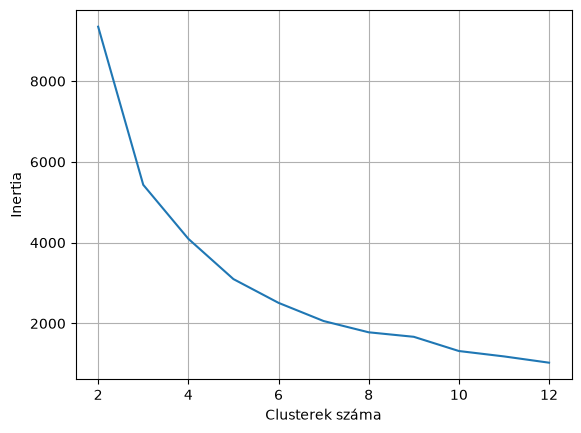

In [178]:
inertia = []
k_values = range(2, 13)

for k in k_values:

    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit_predict(scaled_data_df)
    inertia.append(kmeans.inertia_)

plt.plot(k_values, inertia)
plt.grid(True)
plt.xlabel("Clusterek száma")
plt.ylabel("Inertia")
plt.show()

In [179]:
kmeans = KMeans(n_clusters = 4, random_state=42)
prediction = kmeans.fit_predict(scaled_data)

non_outliers_df["Clusters"] = prediction
non_outliers_df

,CustomerID,TotalValue,Frequency,LastInvoiceDate,Recency,Clusters
0,12346.0,77183.60,1,2011-01-18 10:01:00,325,2
1,12347.0,4310.00,7,2011-12-07 15:52:00,1,1
2,12348.0,1437.24,4,2011-09-25 13:13:00,74,1
3,12349.0,1457.55,1,2011-11-21 09:51:00,18,1
4,12350.0,294.40,1,2011-02-02 16:01:00,309,0
...,...,...,...,...,...,...
4330,18280.0,180.60,1,2011-03-07 09:52:00,277,0
4331,18281.0,80.82,1,2011-06-12 10:53:00,180,0
4332,18282.0,178.05,2,2011-12-02 11:43:00,7,1
4333,18283.0,2088.93,16,2011-12-06 12:02:00,3,2


# Visual

<Axes: xlabel='Frequency', ylabel='Recency'>

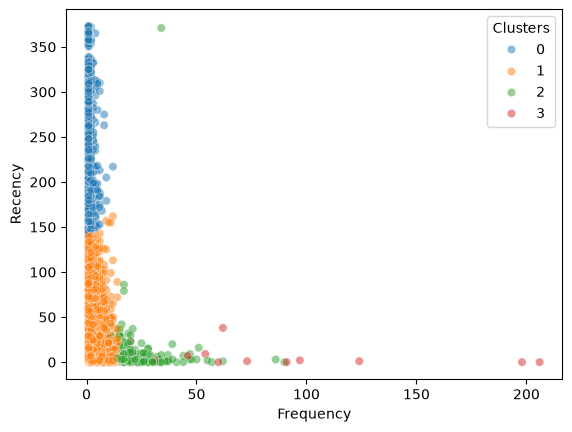

In [180]:
sns.scatterplot(data = non_outliers_df, x="Frequency", y="Recency", hue ="Clusters", palette="tab10", alpha=0.5)

Text(0, 0.5, 'Emberek száma')

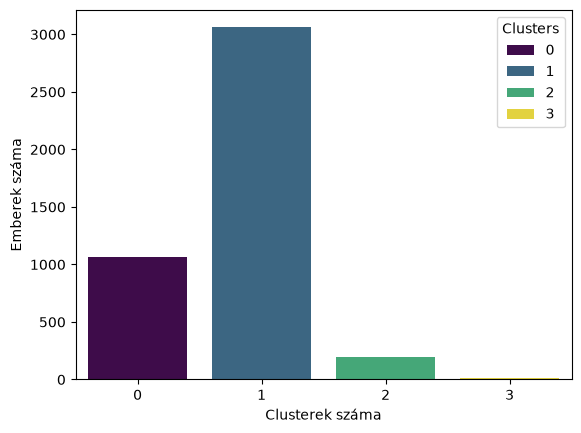

In [181]:
cluster_counts = non_outliers_df['Clusters'].value_counts()
sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette='viridis', hue=cluster_counts.index)
plt.xlabel("Clusterek száma")
plt.ylabel("Emberek száma")

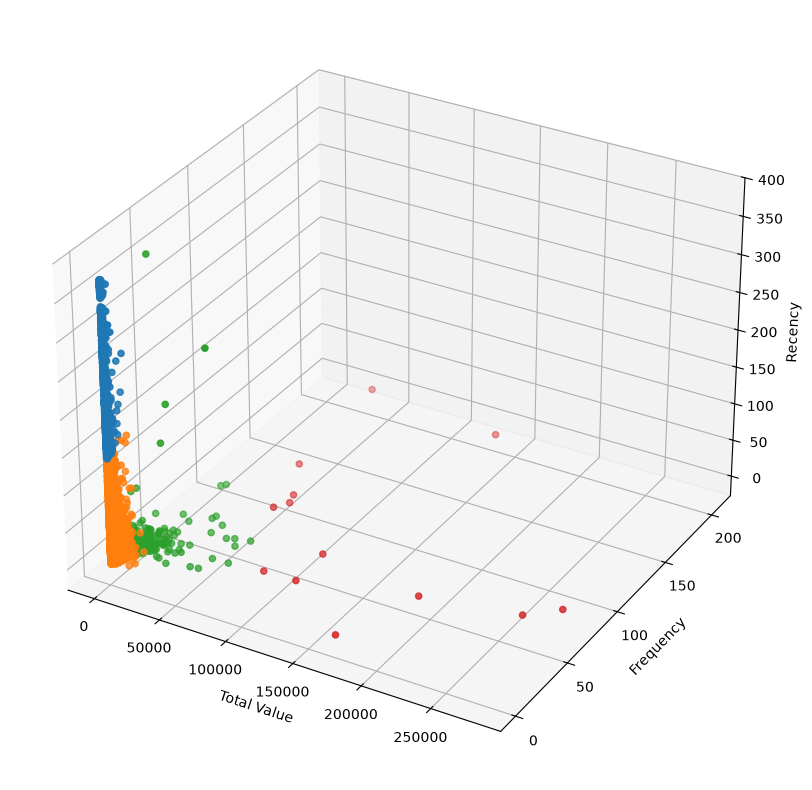

In [182]:
cluster_colors = {0: '#1f77b4',  #Blue
                  1: '#ff7f0e',  #Orange
                  2: '#2ca02c',  #Green
                  3: '#d62728'}  #Red

colors = non_outliers_df['Clusters'].map(cluster_colors)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')

scatter = ax.scatter(non_outliers_df['TotalValue'], 
                     non_outliers_df['Frequency'], 
                     non_outliers_df['Recency'], 
                     c=colors,  # Use mapped solid colors
                     marker='o')

ax.set_xlabel('Total Value')
ax.set_ylabel('Frequency')
ax.set_zlabel('Recency')

plt.show()

# Analysis

Cluster 0: Average in Total Value, and in Frequency but very high in Recency.
Cluster 1: Average in Total Value, and in Frequency, high in recency
Cluster 2: High in Total Value, and in Frequency, low in recency
Cluster 3: Very High in Total Value, and in Frequency, but low in recency



In [183]:
non_outliers_df["Clusters"] = non_outliers_df["Clusters"].replace(0, "Leave")
non_outliers_df["Clusters"] = non_outliers_df["Clusters"].replace(1, "Soon leave")
non_outliers_df["Clusters"] = non_outliers_df["Clusters"].replace(2, "Loyal")
non_outliers_df["Clusters"] = non_outliers_df["Clusters"].replace(3, "Very Loyal")
non_outliers_df

,CustomerID,TotalValue,Frequency,LastInvoiceDate,Recency,Clusters
0,12346.0,77183.60,1,2011-01-18 10:01:00,325,Loyal
1,12347.0,4310.00,7,2011-12-07 15:52:00,1,Soon leave
2,12348.0,1437.24,4,2011-09-25 13:13:00,74,Soon leave
3,12349.0,1457.55,1,2011-11-21 09:51:00,18,Soon leave
4,12350.0,294.40,1,2011-02-02 16:01:00,309,Leave
...,...,...,...,...,...,...
4330,18280.0,180.60,1,2011-03-07 09:52:00,277,Leave
4331,18281.0,80.82,1,2011-06-12 10:53:00,180,Leave
4332,18282.0,178.05,2,2011-12-02 11:43:00,7,Soon leave
4333,18283.0,2088.93,16,2011-12-06 12:02:00,3,Loyal


In [184]:
non_outliers_df.to_excel("customer_clusters.xlsx", index=False)